In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

from superfv.tools.stability_analysis.variables import a, k, h, theta
from superfv.tools.stability_analysis.fv_advection import derive_fv_upwind_Omega_h_over_a
from superfv.tools.stability_analysis.sd_advection import derive_sd_upwind_Omega_h_over_a_matrix

hk = sp.symbols("hk", real=True)

In [2]:
def derive_fv_upwind_knum_error_func(p):
    factor = derive_fv_upwind_Omega_h_over_a(p).subs(theta, k * h) * a / h
    error = factor / (-sp.I * a * k) - 1
    error = error.subs(h * k, hk)
    error_func = sp.lambdify(hk, error, modules="numpy")
    return error_func

In [3]:
def derive_sd_upwind_knum_error_func(p):
    def error_func(hk):
        n = hk.size
        eigenvalues = np.zeros((n, p + 1), dtype=complex)
        for i, hkval in enumerate(hk):
            matrix = derive_sd_upwind_Omega_h_over_a_matrix(hkval, p)
            values = np.linalg.eigvals(matrix)
            eigenvalues[i] = values[np.argsort(abs(values))]

        unfolded_hk = []
        knum_h = []
        for j in range(p + 1):
            branch_knum_h = 1j * eigenvalues[:, j]
            ind = np.where(branch_knum_h.real > 0)
            shifted_hk = hk + (j + 1) // 2 * 2 * np.pi / (p + 1)
            unfolded_hk = np.append(unfolded_hk, shifted_hk[ind])
            knum_h = np.append(knum_h, branch_knum_h[ind])
        for j in range(p + 1):
            branch_knum_h = 1j * eigenvalues[:, j]
            ind = np.where(branch_knum_h.real < 0)
            shifted_hk = hk - (j + 1) // 2 * 2 * np.pi / (p + 1)
            unfolded_hk = np.append(unfolded_hk, shifted_hk[ind])
            knum_h = np.append(knum_h, branch_knum_h[ind])

        error = knum_h / unfolded_hk - 1
        ind = np.argsort(unfolded_hk)
        return unfolded_hk[ind], error[ind]

    return error_func

<lambdifygenerated-1>:2: RuntimeWarning: invalid value encountered in divide
  return -1 + 1j*(-37/24*1j*sin(hk) + (1/3)*1j*sin(2*hk) - 1/24*1j*sin(3*hk) + (5/8)*cos(hk) - 1/4*cos(2*hk) + (1/24)*cos(3*hk) - 5/12)/hk
<lambdifygenerated-2>:2: RuntimeWarning: invalid value encountered in divide
  return -1 + (1/1680)*1j*(-1j*sin(5*hk) + cos(5*hk))*(-33*1j*sin(hk) + 172*1j*sin(2*hk) - 588*1j*sin(3*hk) + 1722*1j*sin(4*hk) - 378*1j*sin(5*hk) - 1092*1j*sin(6*hk) + 228*1j*sin(7*hk) - 37*1j*sin(8*hk) + 3*1j*sin(9*hk) - 33*cos(hk) + 172*cos(2*hk) - 588*cos(3*hk) + 1722*cos(4*hk) - 378*cos(5*hk) - 1092*cos(6*hk) + 228*cos(7*hk) - 37*cos(8*hk) + 3*cos(9*hk) + 3)/hk
/var/folders/y9/m318q_ps0l19lz859k2_tfr00000gn/T/ipykernel_97058/610215086.py:25: RuntimeWarning: divide by zero encountered in divide
  error = knum_h / unfolded_hk - 1
/var/folders/y9/m318q_ps0l19lz859k2_tfr00000gn/T/ipykernel_97058/2382859556.py:8: RuntimeWarning: invalid value encountered in multiply
  return np.abs(x.real) + 1j * n

Trapezoid integrals of errors on half domain away from singularity:
FV4 real: 6.90e-01 imag: 5.38e-01
SD4 real: 4.68e-01 imag: 1.01e+00
FV8 real: 5.49e-01 imag: 2.72e-01
SD8 real: 2.83e-01 imag: 1.03e+00


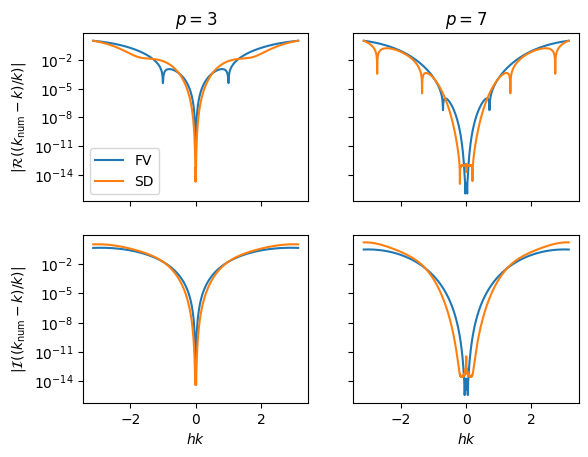

In [4]:
hk_array = np.linspace(-np.pi + 1e-4, np.pi - 1e-4, 1025)
fv_trace_p3 = derive_fv_upwind_knum_error_func(3)(hk_array)
fv_trace_p7 = derive_fv_upwind_knum_error_func(7)(hk_array)
sd_hk_p3, sd_trace_p3 = derive_sd_upwind_knum_error_func(3)(hk_array / (3 + 1))
sd_hk_p7, sd_trace_p7 = derive_sd_upwind_knum_error_func(7)(hk_array / (7 + 1))

def abs_comp(x):
    return np.abs(x.real) + 1j * np.abs(x.imag)

fv_trace_p3 = abs_comp(fv_trace_p3)
fv_trace_p7 = abs_comp(fv_trace_p7)
sd_trace_p3 = abs_comp(sd_trace_p3)
sd_trace_p7 = abs_comp(sd_trace_p7)

fig, axs = plt.subplots(2, 2, sharex=True, sharey='row')
for ax in axs[1,:]:
    ax.set_xlabel(r"$hk$")
for ax in axs[:, 0]:
    ax.set_yscale("log")
axs[0, 0].set_ylabel(r"$|\mathcal{R}((k_{\text{num}}-k)/k)|$")
axs[1, 0].set_ylabel(r"$|\mathcal{I}((k_{\text{num}}-k)/k)|$")
axs[0, 0].set_title(r"$p=3$")
axs[0, 1].set_title(r"$p=7$")

axs[0, 0].plot(hk_array, fv_trace_p3.real, label="FV")
axs[1, 0].plot(hk_array, fv_trace_p3.imag)
axs[0, 1].plot(hk_array, fv_trace_p7.real)
axs[1, 1].plot(hk_array, fv_trace_p7.imag)

axs[0, 0].plot(sd_hk_p3, sd_trace_p3.real, label="SD")
axs[1, 0].plot(sd_hk_p3, sd_trace_p3.imag)
axs[0, 1].plot(sd_hk_p7, sd_trace_p7.real)
axs[1, 1].plot(sd_hk_p7, sd_trace_p7.imag)

axs[0, 0].legend()


print("Trapezoid integrals of errors on half domain away from singularity:")
half = slice(len(hk_array) // 2 + 1, None)
print(f"FV4 real: {np.trapezoid(fv_trace_p3.real[half], hk_array[half]):.2e} imag: {np.trapezoid(fv_trace_p3.imag[half], hk_array[half]):.2e}")
half = slice(len(sd_hk_p3) // 2, None)
print(f"SD4 real: {np.trapezoid(sd_trace_p3.real[half], sd_hk_p3[half]):.2e} imag: {np.trapezoid(sd_trace_p3.imag[half], sd_hk_p3[half]):.2e}")
half = slice(len(hk_array) // 2 + 1, None)
print(f"FV8 real: {np.trapezoid(fv_trace_p7.real[half], hk_array[half]):.2e} imag: {np.trapezoid(fv_trace_p7.imag[half], hk_array[half]):.2e}")
half = slice(len(sd_hk_p7) // 2, None)
print(f"SD8 real: {np.trapezoid(sd_trace_p7.real[half], sd_hk_p7[half]):.2e} imag: {np.trapezoid(sd_trace_p7.imag[half], sd_hk_p7[half]):.2e}")

fig.savefig("../out/modifed_wavenumber_analysis.pdf", bbox_inches="tight")